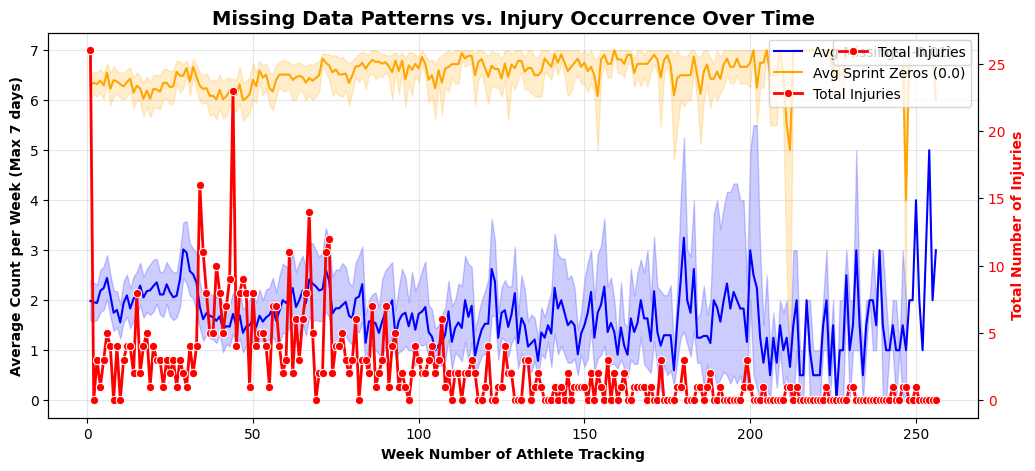

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar o dataset original
df_raw = pd.read_csv("../data/daily_injury_data.csv")
df_raw = df_raw.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# 2. Separar colunas (Corrigido o erro de sintaxe 'psychology')
subjective_cols = [col for col in df_raw.columns if 'perceived' in col]
objective_cols = [col for col in df_raw.columns if col not in subjective_cols and col not in ['Athlete ID', 'Date', 'injury']]

# 3. Criar a métrica de "Semanas"
df_raw['Reading_Index'] = df_raw.groupby('Athlete ID').cumcount()
df_raw['Week_Number'] = (df_raw['Reading_Index'] // 7) + 1

# 4. Agregações (NOVO: Adicionado a contagem de lesões 'injuries')
zeros_analysis = df_raw.groupby(['Athlete ID', 'Week_Number']).agg(
    total_days=('Date', 'count'),
    sprint_zeros=('km sprinting', lambda x: (x == 0).sum()),
    exertion_zeros=('perceived exertion', lambda x: (x == 0).sum()),
    exertion_missings=('perceived exertion', lambda x: (x == -0.01).sum()),
    injuries=('injury', 'sum')  # <-- Nova linha para contar lesões
).reset_index()

# Calcular o total global de lesões por semana (somando todos os atletas)
weekly_injuries = zeros_analysis.groupby('Week_Number')['injuries'].sum().reset_index()

# 5. Visualização com Duplo Eixo Y (Twin Axes)
fig, ax1 = plt.subplots(figsize=(12, 5))

# Eixo Y Principal (Esquerda) - Padrões de Preenchimento (escala 0 a 7)
sns.lineplot(data=zeros_analysis, x='Week_Number', y='exertion_missings', estimator='mean', 
             color='blue', label='Avg Missings (-0.01)', ax=ax1)
sns.lineplot(data=zeros_analysis, x='Week_Number', y='sprint_zeros', estimator='mean', 
             color='orange', label='Avg Sprint Zeros (0.0)', ax=ax1)

ax1.set_xlabel('Week Number of Athlete Tracking', fontweight='bold')
ax1.set_ylabel('Average Count per Week (Max 7 days)', color='black', fontweight='bold')
ax1.grid(True, alpha=0.3)

# Eixo Y Secundário (Direita) - Total de Lesões
ax2 = ax1.twinx()
sns.lineplot(data=weekly_injuries, x='Week_Number', y='injuries', 
             color='red', marker='o', linewidth=2, label='Total Injuries', ax=ax2)

ax2.set_ylabel('Total Number of Injuries', color='red', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='red')

# Juntar as legendas dos dois eixos num só painel
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

plt.title('Missing Data Patterns vs. Injury Occurrence Over Time', fontweight='bold', fontsize=14)
plt.show()

--- Starting Athlete Training Frequency Profiling ---

Athlete Distribution by Training Group:
Training_Cluster
3-5 Days (Medium Frequency)          52
6-7 Days (High Frequency)            19
< 3 Days (Low Frequency/Outliers)     3
Name: count, dtype: int64

Average Injuries per Group:
Training_Cluster
3-5 Days (Medium Frequency)          8.21
6-7 Days (High Frequency)            8.00
< 3 Days (Low Frequency/Outliers)    1.33
Name: total_injuries, dtype: float64


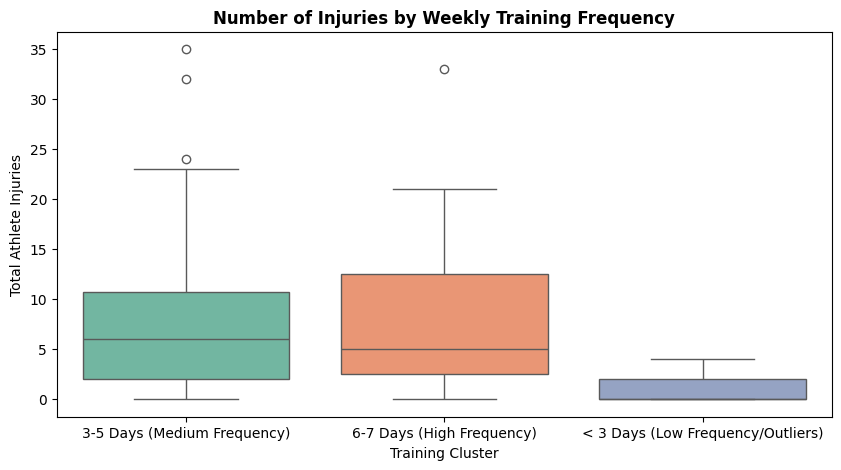

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Starting Athlete Training Frequency Profiling ---")

# 1. Load the data
df_freq = pd.read_csv("../data/daily_injury_data.csv")
df_freq = df_freq.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# 2. Define a "Training Day" (any day with km > 0, sessions > 0, or strength > 0)
df_freq['is_training_day'] = ((df_freq['total km'] > 0) | 
                              (df_freq['strength training'] > 0) | 
                              (df_freq['nr. sessions'] > 0)).astype(int)

# 3. Group by athlete to calculate average training days per week
athlete_profile = df_freq.groupby('Athlete ID').agg(
    total_recorded_days=('Date', 'count'),
    total_training_days=('is_training_day', 'sum'),
    total_injuries=('injury', 'sum')
).reset_index()

# Calculate the statistical average of training days per week
athlete_profile['avg_days_per_week'] = (athlete_profile['total_training_days'] / athlete_profile['total_recorded_days']) * 7

# 4. Create the categories (Clusters) suggested by the professor
def categorize_freq(days):
    if days >= 5.5:
        return '6-7 Days (High Frequency)'
    elif days >= 2.5:
        return '3-5 Days (Medium Frequency)'
    else:
        return '< 3 Days (Low Frequency/Outliers)'

athlete_profile['Training_Cluster'] = athlete_profile['avg_days_per_week'].apply(categorize_freq)

# 5. Print the summary for the professor
print("\nAthlete Distribution by Training Group:")
print(athlete_profile['Training_Cluster'].value_counts())

print("\nAverage Injuries per Group:")
print(athlete_profile.groupby('Training_Cluster')['total_injuries'].mean().round(2))

# 6. Visualize the difference (Fixed the Seaborn warning)
plt.figure(figsize=(10, 5))
sns.boxplot(data=athlete_profile, x='Training_Cluster', y='total_injuries', 
            hue='Training_Cluster', palette='Set2', legend=False)
plt.title('Number of Injuries by Weekly Training Frequency', fontweight='bold')
plt.ylabel('Total Athlete Injuries')
plt.xlabel('Training Cluster')
plt.show()

# Save this new categorization into the original dataset (useful for the ML model later!)
df_freq = df_freq.merge(athlete_profile[['Athlete ID', 'Training_Cluster']], on='Athlete ID', how='left')

As lesões estão mais relacionadas às pessoas treinam 3-5 dias e 6-7 dias

--- Relating Training Clusters with Workload Profiles ---


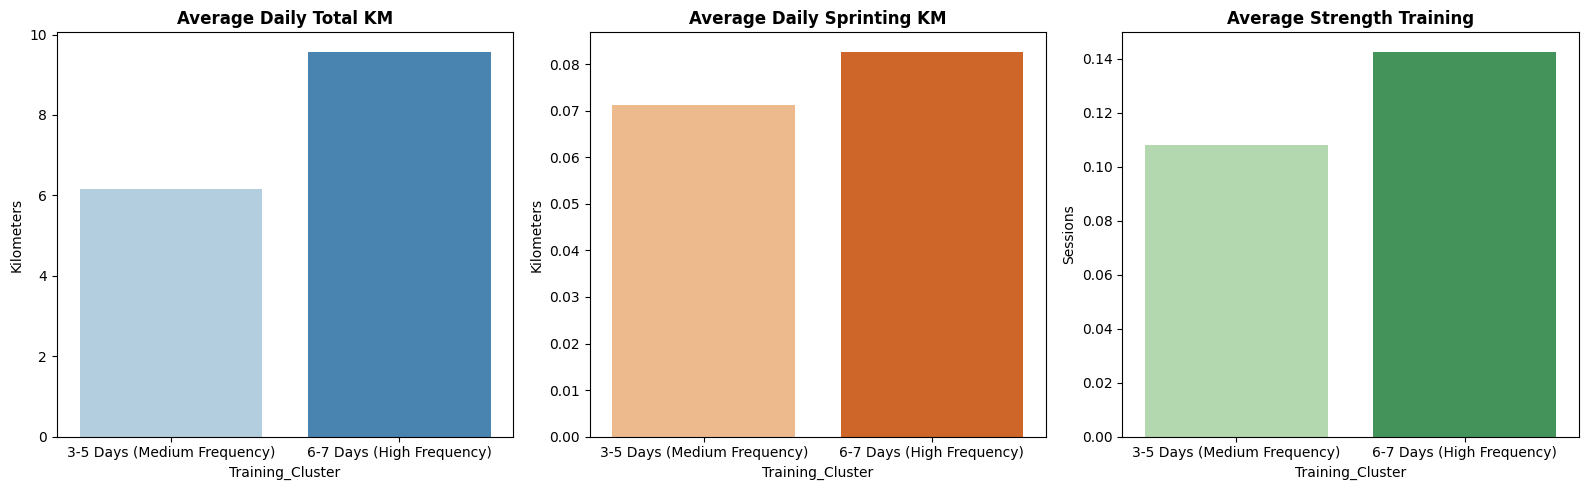

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Relating Training Clusters with Workload Profiles ---")

workload_analysis = df_freq.groupby('Training_Cluster').agg(
    avg_daily_km=('total km', 'mean'),
    avg_daily_sprint=('km sprinting', 'mean'),
    avg_strength_sessions=('strength training', 'mean')
).reset_index()

workload_analysis = workload_analysis[workload_analysis['Training_Cluster'].str.contains('3-5|6-7')]

# Visualize the Workload Differences (Warnings Fixed!)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=workload_analysis, x='Training_Cluster', y='avg_daily_km', 
            hue='Training_Cluster', ax=axes[0], palette='Blues', legend=False)
axes[0].set_title('Average Daily Total KM', fontweight='bold')
axes[0].set_ylabel('Kilometers')

sns.barplot(data=workload_analysis, x='Training_Cluster', y='avg_daily_sprint', 
            hue='Training_Cluster', ax=axes[1], palette='Oranges', legend=False)
axes[1].set_title('Average Daily Sprinting KM', fontweight='bold')
axes[1].set_ylabel('Kilometers')

sns.barplot(data=workload_analysis, x='Training_Cluster', y='avg_strength_sessions', 
            hue='Training_Cluster', ax=axes[2], palette='Greens', legend=False)
axes[2].set_title('Average Strength Training', fontweight='bold')
axes[2].set_ylabel('Sessions')

plt.tight_layout()
plt.show()

--- Explorando Relações: Acute:Chronic Workload Ratio (ACWR) ---


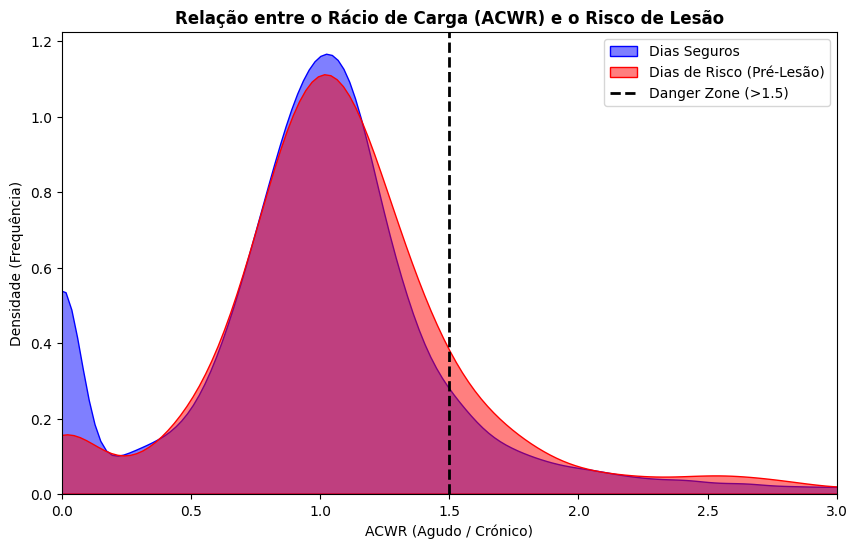


Média do Rácio ACWR (Seguros vs Risco):
Risk_Zone
0    1.019
1    1.117
Name: ACWR_Total_KM, dtype: float64


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Explorando Relações: Acute:Chronic Workload Ratio (ACWR) ---")

# 1. Carregar os dados limpos
df_acwr = pd.read_csv("../data/daily_injury_data.csv")
df_acwr = df_acwr.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# Recriar a Risk_Zone (Target)
df_acwr['Risk_Zone'] = df_acwr['injury']
for i in range(1, 4):
    future_injury = df_acwr.groupby('Athlete ID')['injury'].shift(-i).fillna(0)
    df_acwr['Risk_Zone'] = (df_acwr['Risk_Zone'] | future_injury.astype(int))

# 2. Calcular a Carga Aguda (Soma de 7 dias) para o Total de KMs
df_acwr['Acute_Load_7d'] = df_acwr.groupby('Athlete ID')['total km'].transform(lambda x: x.rolling(window=7, min_periods=1).sum())

# 3. Calcular a Carga Crónica (Soma de 28 dias a dividir por 4 semanas = média semanal do último mês)
df_acwr['Chronic_Load_28d'] = df_acwr.groupby('Athlete ID')['total km'].transform(lambda x: x.rolling(window=28, min_periods=7).sum() / 4)

# 4. Calcular o ACWR (Rácio Agudo / Crónico)
# Evitar divisão por zero somando 0.001
df_acwr['ACWR_Total_KM'] = df_acwr['Acute_Load_7d'] / (df_acwr['Chronic_Load_28d'] + 0.001)

# Filtrar valores absurdos que acontecem nas primeiras semanas de treino quando a carga crónica ainda é zero
df_acwr = df_acwr[df_acwr['ACWR_Total_KM'] < 5]

# 5. Visualizar a relação do Rácio com as Lesões
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_acwr[df_acwr['Risk_Zone'] == 0], x='ACWR_Total_KM', fill=True, color='blue', label='Dias Seguros', alpha=0.5)
sns.kdeplot(data=df_acwr[df_acwr['Risk_Zone'] == 1], x='ACWR_Total_KM', fill=True, color='red', label='Dias de Risco (Pré-Lesão)', alpha=0.5)

# A famosa "Zona de Perigo" (Sweet Spot é entre 0.8 e 1.3, Danger Zone é > 1.5)
plt.axvline(1.5, color='black', linestyle='--', linewidth=2, label='Danger Zone (>1.5)')

plt.title('Relação entre o Rácio de Carga (ACWR) e o Risco de Lesão', fontweight='bold')
plt.xlabel('ACWR (Agudo / Crónico)')
plt.ylabel('Densidade (Frequência)')
plt.legend()
plt.xlim(0, 3)
plt.show()

# Imprimir as estatísticas
print("\nMédia do Rácio ACWR (Seguros vs Risco):")
print(df_acwr.groupby('Risk_Zone')['ACWR_Total_KM'].mean().round(3))

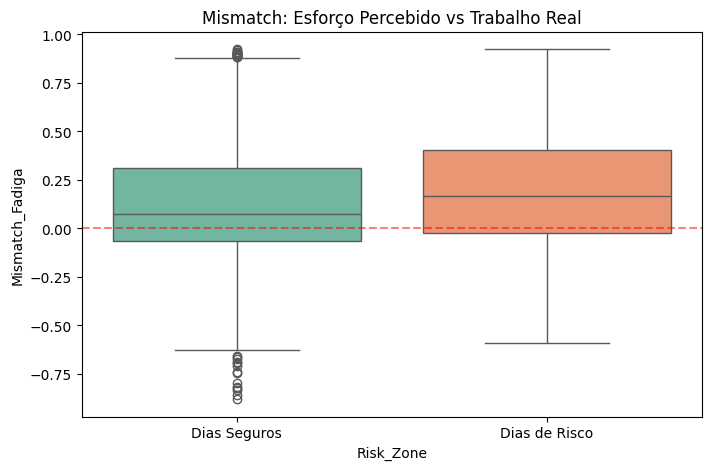

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

df_mismatch = pd.read_csv("../data/daily_injury_data.csv")
df_mismatch = df_mismatch.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# Recriar a Risk_Zone
df_mismatch['Risk_Zone'] = df_mismatch['injury']
for i in range(1, 4):
    future_injury = df_mismatch.groupby('Athlete ID')['injury'].shift(-i).fillna(0)
    df_mismatch['Risk_Zone'] = (df_mismatch['Risk_Zone'] | future_injury.astype(int))

# 1. Filtrar dias de treino válidos
df_treino = df_mismatch[(df_mismatch['total km'] > 0) & (df_mismatch['perceived exertion'] >= 0)].copy()

# 2. Normalizar as duas colunas (0 a 1)
scaler = MinMaxScaler()
df_treino[['km_scaled', 'exertion_scaled']] = scaler.fit_transform(df_treino[['total km', 'perceived exertion']])

# 3. Criar a métrica de Mismatch
# Positivo = Sentiu mais esforço do que o trabalho que fez
df_treino['Mismatch_Fadiga'] = df_treino['exertion_scaled'] - df_treino['km_scaled']

# 4. Ver a relação com as lesões
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_treino, x='Risk_Zone', y='Mismatch_Fadiga', hue='Risk_Zone', palette='Set2', legend=False)
plt.title('Mismatch: Esforço Percebido vs Trabalho Real')
plt.xticks([0, 1], ['Dias Seguros', 'Dias de Risco'])
plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.show()

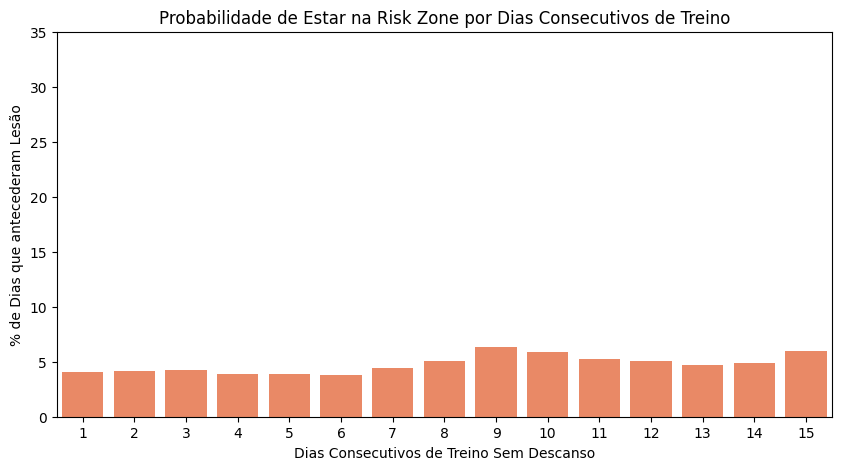

In [15]:
# 1. Marcar dias de treino (KMs > 0 ou Força > 0 ou Sessões > 0)
df_mismatch['is_training'] = ((df_mismatch['total km'] > 0) | 
                              (df_mismatch['strength training'] > 0) | 
                              (df_mismatch['nr. sessions'] > 0)).astype(int)

# 2. Criar blocos/grupos de treino consecutivo (separados por dias de descanso)
# Cada vez que 'is_training' é 0, criamos um novo identificador de bloco
df_mismatch['rest_day_block'] = (df_mismatch['is_training'] == 0).cumsum()

# 3. Contar os dias consecutivos dentro de cada bloco (apenas para dias de treino)
df_mismatch['dias_consecutivos'] = df_mismatch.groupby(['Athlete ID', 'rest_day_block'])['is_training'].cumsum()

# Os dias de descanso vão ficar com o valor de is_training (que é 0)
df_mismatch.loc[df_mismatch['is_training'] == 0, 'dias_consecutivos'] = 0

# 4. Analisar em que "Dia Consecutivo" o risco de lesão é maior
# Agrupar pelos dias consecutivos e ver a taxa de risco
taxa_risco = df_mismatch[df_mismatch['dias_consecutivos'] > 0].groupby('dias_consecutivos')['Risk_Zone'].mean() * 100

plt.figure(figsize=(10, 5))
sns.barplot(x=taxa_risco.index, y=taxa_risco.values, color='coral')
plt.title('Probabilidade de Estar na Risk Zone por Dias Consecutivos de Treino')
plt.xlabel('Dias Consecutivos de Treino Sem Descanso')
plt.ylabel('% de Dias que antecederam Lesão')
plt.xlim(-0.5, 14.5) # Limitar a 15 dias seguidos para ser legível
plt.show()

In [18]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# 1. Calcular o Mismatch no df_final
scaler_temp = MinMaxScaler()
df_final_temp = df_final[['total km', 'perceived exertion']].replace(-0.01, 0).fillna(0)
df_final[['km_scaled', 'exertion_scaled']] = scaler_temp.fit_transform(df_final_temp)

df_final['Mismatch_Fadiga'] = df_final['exertion_scaled'] - df_final['km_scaled']
df_final = df_final.drop(columns=['km_scaled', 'exertion_scaled'])

# 2. Calcular os Dias Consecutivos no df_final (Faltava este passo!)
df_final['is_training'] = ((df_final['total km'] > 0) | 
                           (df_final['strength training'] > 0) | 
                           (df_final['nr. sessions'] > 0)).astype(int)

df_final['rest_day_block'] = (df_final['is_training'] == 0).cumsum()
df_final['dias_consecutivos'] = df_final.groupby(['Athlete ID', 'rest_day_block'])['is_training'].cumsum()
df_final.loc[df_final['is_training'] == 0, 'dias_consecutivos'] = 0

# Limpar as colunas temporárias
df_final = df_final.drop(columns=['is_training', 'rest_day_block'])

# 3. Criar o Alarme de Fadiga Acumulada
# ATENÇÃO: Substitui o '5' pelo dia da barra mais alta que viste no teu gráfico!
dia_critico = 5 
df_final['Alarme_Dias_Consecutivos'] = (df_final['dias_consecutivos'] >= dia_critico).astype(int)

print(df_final[['Athlete ID', 'Risk_Zone', 'Mismatch_Fadiga', 'dias_consecutivos', 'Alarme_Dias_Consecutivos']].head(10))

   Athlete ID  Risk_Zone  Mismatch_Fadiga  dias_consecutivos  \
0           0          0         0.006243                  1   
1           0          0         0.000000                  0   
2           0          0         0.100000                  1   
3           0          0         0.000000                  0   
4           0          0         0.080000                  1   
5           0          0        -0.183381                  2   
6           0          0         0.100000                  3   
7           0          0         0.006977                  4   
8           0          0         0.000000                  0   
9           0          0         0.100000                  1   

   Alarme_Dias_Consecutivos  
0                         0  
1                         0  
2                         0  
3                         0  
4                         0  
5                         0  
6                         0  
7                         0  
8                        

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from imblearn.combine import SMOTEENN
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, f1_score, precision_score
from sklearn.preprocessing import MinMaxScaler

print("--- Pipeline Completo de Validação com Todas as Novas Features ---")

# 1. Carregar os dados base
df_completo = pd.read_csv("../data/daily_injury_data.csv")
df_completo = df_completo.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# Criar a Risk_Zone (Janela de 3 dias pré-lesão)
df_completo['Risk_Zone'] = df_completo['injury']
for i in range(1, 4):
    future_injury = df_completo.groupby('Athlete ID')['injury'].shift(-i).fillna(0)
    df_completo['Risk_Zone'] = (df_completo['Risk_Zone'] | future_injury.astype(int))

# --- FEATURE 1: Athlete Compliance (Taxa de Preenchimento) ---
df_completo['questionnaire_filled'] = (df_completo['perceived exertion'] != -0.01).astype(int)
df_completo['cum_filled'] = df_completo.groupby('Athlete ID')['questionnaire_filled'].cumsum()
df_completo['cum_days'] = df_completo.groupby('Athlete ID').cumcount() + 1
df_completo['athlete_compliance'] = df_completo['cum_filled'] / df_completo['cum_days']
df_completo = df_completo.drop(columns=['questionnaire_filled', 'cum_filled', 'cum_days'])

# --- FEATURE 2: Training Cluster (Perfil de Frequência Semanal) ---
df_completo['is_training_day'] = ((df_completo['total km'] > 0) | 
                                 (df_completo['strength training'] > 0) | 
                                 (df_completo['nr. sessions'] > 0)).astype(int)

athlete_profile = df_completo.groupby('Athlete ID').agg(
    total_recorded_days=('Date', 'count'),
    total_training_days=('is_training_day', 'sum')
).reset_index()
athlete_profile['avg_days_per_week'] = (athlete_profile['total_training_days'] / athlete_profile['total_recorded_days']) * 7

def categorize_freq(days):
    if days >= 5.5: return 'High_Freq'
    elif days >= 2.5: return 'Med_Freq'
    else: return 'Low_Freq'

athlete_profile['Training_Cluster'] = athlete_profile['avg_days_per_week'].apply(categorize_freq)
df_completo = df_completo.merge(athlete_profile[['Athlete ID', 'Training_Cluster']], on='Athlete ID', how='left')
df_completo = df_completo.drop(columns=['is_training_day'])

# --- FEATURE 3: Mismatch Fadiga (Esforço Subjetivo vs Trabalho Real) ---
scaler_temp = MinMaxScaler()
df_temp_clean = df_completo[['total km', 'perceived exertion']].replace(-0.01, 0).fillna(0)
df_completo[['km_scaled', 'exertion_scaled']] = scaler_temp.fit_transform(df_temp_clean)
df_completo['Mismatch_Fadiga'] = df_completo['exertion_scaled'] - df_completo['km_scaled']
df_completo = df_completo.drop(columns=['km_scaled', 'exertion_scaled'])

# --- FEATURE 4: Alarme de Dias Consecutivos Sem Descanso ---
df_completo['is_training'] = ((df_completo['total km'] > 0) | 
                              (df_completo['strength training'] > 0) | 
                              (df_completo['nr. sessions'] > 0)).astype(int)

df_completo['rest_day_block'] = (df_completo['is_training'] == 0).cumsum()
df_completo['dias_consecutivos'] = df_completo.groupby(['Athlete ID', 'rest_day_block'])['is_training'].cumsum()
df_completo.loc[df_completo['is_training'] == 0, 'dias_consecutivos'] = 0
df_completo = df_completo.drop(columns=['is_training', 'rest_day_block'])

# Nota: Substitui o 5 pelo limiar crítico ideal visto no teu gráfico de barras
dia_critico = 5  
df_completo['Alarme_Dias_Consecutivos'] = (df_completo['dias_consecutivos'] >= dia_critico).astype(int)
df_completo = df_completo.drop(columns=['dias_consecutivos'])

# --- PREPARAÇÃO DOS DADOS PARA MODELAÇÃO ---
# Codificação One-Hot para as categorias do cluster de treino
df_completo = pd.get_dummies(df_completo, columns=['Training_Cluster'], drop_first=False)

# Divisão de matrizes (Remover identificadores e target)
X_cv = df_completo.drop(columns=['Athlete ID', 'Date', 'injury', 'Risk_Zone'])
y_cv = df_completo['Risk_Zone']
groups_cv = df_completo['Athlete ID']

# Tratar valores sentinela (-0.01) e nulos no X_cv global antes do escalonamento
X_cv = X_cv.fillna(0).replace(-0.01, 0)

# Escalonamento MinMax de todas as features para estabilidade da Regressão Logística
scaler_cv = MinMaxScaler()
X_cv_scaled = scaler_cv.fit_transform(X_cv)
X_cv = pd.DataFrame(X_cv_scaled, columns=X_cv.columns)

# --- PIPELINE DE VALIDAÇÃO CRUZADA (GroupKFold + SMOTEENN) ---
gkf = GroupKFold(n_splits=5)
smote_enn = SMOTEENN(random_state=42)

recalls, precisions, f1_scores = [], [], []

print("A executar o treino e validação por dobra (fold)...")
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_cv, y_cv, groups_cv)):
    X_train_f, X_val_f = X_cv.iloc[train_idx], X_cv.iloc[val_idx]
    y_train_f, y_val_f = y_cv.iloc[train_idx], y_cv.iloc[val_idx]
    
    # Reamostragem/Balanceamento apenas na dobra de treino para evitar data leakage
    X_train_res, y_train_res = smote_enn.fit_resample(X_train_f, y_train_f)
    
    # Inicialização do Modelo com pesos balanceados internos
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(X_train_res, y_train_res)
    
    # Obtenção de probabilidades e aplicação do limiar (threshold) de 0.45
    y_proba = model.predict_proba(X_val_f)[:, 1]
    y_pred = (y_proba >= 0.45).astype(int) 
    
    recalls.append(recall_score(y_val_f, y_pred, zero_division=0))
    precisions.append(precision_score(y_val_f, y_pred, zero_division=0))
    f1_scores.append(f1_score(y_val_f, y_pred, zero_division=0))
    
    print(f"Fold {fold+1} -> Recall: {recalls[-1]:.2%}, Precision: {precisions[-1]:.2%}, F1-Score: {f1_scores[-1]:.2%}")

print("\n--- Desempenho Final Acumulado com Todas as Novas Características ---")
print(f"Média Recall:    {np.mean(recalls):.2%} (+/- {np.std(recalls):.2%})")
print(f"Média Precision: {np.mean(precisions):.2%} (+/- {np.std(precisions):.2%})")
print(f"Média F1-Score:  {np.mean(f1_scores):.2%} (+/- {np.std(f1_scores):.2%})")

--- Pipeline Completo de Validação com Todas as Novas Features ---
A executar o treino e validação por dobra (fold)...
Fold 1 -> Recall: 68.93%, Precision: 6.68%, F1-Score: 12.19%
Fold 2 -> Recall: 62.05%, Precision: 3.37%, F1-Score: 6.39%
Fold 3 -> Recall: 67.77%, Precision: 4.54%, F1-Score: 8.50%
Fold 4 -> Recall: 68.41%, Precision: 5.37%, F1-Score: 9.96%
Fold 5 -> Recall: 67.46%, Precision: 5.13%, F1-Score: 9.53%

--- Desempenho Final Acumulado com Todas as Novas Características ---
Média Recall:    66.93% (+/- 2.49%)
Média Precision: 5.02% (+/- 1.08%)
Média F1-Score:  9.31% (+/- 1.89%)


--- A Gerar Visualizações Finais do Modelo (Regressão Logística) ---


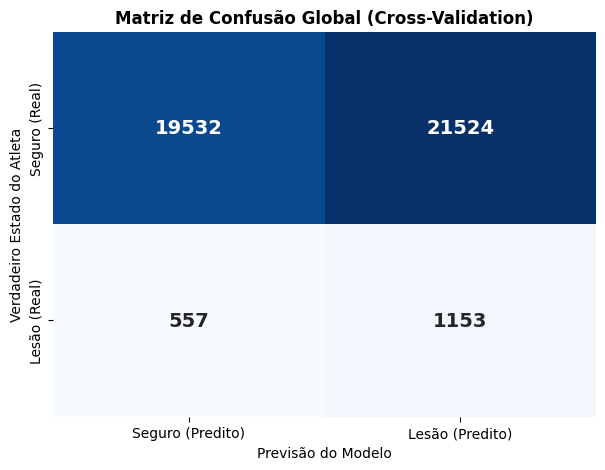

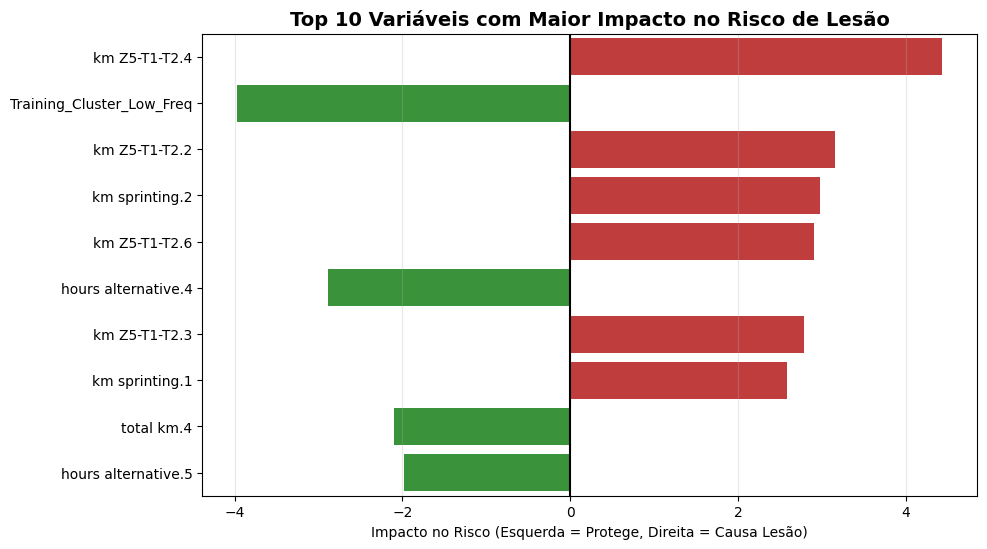

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from imblearn.combine import SMOTEENN

print("--- A Gerar Visualizações Finais do Modelo (Regressão Logística) ---")

# 1. Variáveis para acumular os resultados de todas as dobras (folds)
y_true_all = []
y_pred_all = []

# 2. Re-executar o loop do GroupKFold apenas para recolher as previsões
gkf = GroupKFold(n_splits=5)
smote_enn = SMOTEENN(random_state=42)

for train_idx, val_idx in gkf.split(X_cv, y_cv, groups_cv):
    X_train_f, X_val_f = X_cv.iloc[train_idx], X_cv.iloc[val_idx]
    y_train_f, y_val_f = y_cv.iloc[train_idx], y_cv.iloc[val_idx]
    
    X_train_res, y_train_res = smote_enn.fit_resample(X_train_f, y_train_f)
    
    # Regressão Logística
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(X_train_res, y_train_res)
    
    y_proba = model.predict_proba(X_val_f)[:, 1]
    y_pred = (y_proba >= 0.45).astype(int) 
    
    y_true_all.extend(y_val_f)
    y_pred_all.extend(y_pred)

# --- GRÁFICO 1: MATRIZ DE CONFUSÃO ---
cm = confusion_matrix(y_true_all, y_pred_all)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['Seguro (Predito)', 'Lesão (Predito)'], 
            yticklabels=['Seguro (Real)', 'Lesão (Real)'],
            annot_kws={"size": 14, "weight": "bold"})
plt.title('Matriz de Confusão Global (Cross-Validation)', fontweight='bold')
plt.ylabel('Verdadeiro Estado do Atleta')
plt.xlabel('Previsão do Modelo')
plt.show()

# --- GRÁFICO 2: IMPORTÂNCIA DAS VARIÁVEIS (FEATURE IMPORTANCE) ---
# Para ter a importância real das features, treinamos um modelo final com todos os dados
X_res_final, y_res_final = smote_enn.fit_resample(X_cv, y_cv)
final_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
final_model.fit(X_res_final, y_res_final)

# Extrair os coeficientes (pesos) que a Regressão Logística deu a cada variável
importances = final_model.coef_[0]
feature_names = X_cv.columns

# Juntar num DataFrame e ordenar pelos mais impactantes
df_importances = pd.DataFrame({'Feature': feature_names, 'Peso': importances})
df_importances['Peso Absoluto'] = df_importances['Peso'].abs()
df_importances = df_importances.sort_values(by='Peso Absoluto', ascending=False).head(10) # Top 10 variáveis

plt.figure(figsize=(10, 6))
# Cores: Vermelho se aumenta o risco de lesão, Verde se protege contra lesões
cores = ['#d62728' if peso > 0 else '#2ca02c' for peso in df_importances['Peso']]

sns.barplot(data=df_importances, x='Peso', y='Feature', palette=cores, hue='Feature', legend=False)
plt.title('Top 10 Variáveis com Maior Impacto no Risco de Lesão', fontweight='bold', fontsize=14)
plt.xlabel('Impacto no Risco (Esquerda = Protege, Direita = Causa Lesão)')
plt.ylabel('')
plt.axvline(0, color='black', linewidth=1.5)
plt.grid(axis='x', alpha=0.3)
plt.show()